# S8: normalized partial whitening

## Краткий итог

β=0,5 выбрана для GCC и SRP. Harmonic L: **51,184%→15,154%** (GCC),
**44,783%→18,958%** (SRP). Guardrails пройдены: оба варианта перспективны
для отдельной calibration. **Harmonic tracking не подтверждён**, availability0%;
улучшение направлений не дало устойчивого сопровождения. 16audio/8replay,
36,62мин workers, без technical stop. Точные значения ниже — из saved artifacts.
Известные spatial/radial записи Gazebo, новые acoustic realizations; не новые
независимые полёты. Каждый метод оценивается отдельно. Ambiguity gate выключен.

## Context & Methods

$\Psi_{ij}^{(\beta)}=\Psi_{ij}^{base}(|C_{ij}|/\max_{k\in K}|C_{ij}|)^{1-\beta}$,
$\beta\in\{1,0.75,0.5\}$; при β=1 дополнительные веса явно единичные.
$L=(N_{invalid}+N_{valid,error>10^\circ})/N_{planned}$.

### Key Assumptions

Одна continuous source/noise realization; overlapping frames зависимы.
Equal stream/station cell macro, отдельно all frames / stride32.
Параметры выбраны только на development, отдельный freeze commit до evaluation.
Прежняя R калибрована для baseline: uncertainty нового frontend не квалифицирована.
Конечная скорость звука, 1/r, +10dB fixed reference noise на100м, прежняя ENU geometry.
Источник приближён синтетическим waveform, ветер и отражения не моделируются.

## Data

Источники: `PARTIAL_WHITENING_PROTOCOL_MANIFEST.json`,
`results/partial_whitening_001/study_manifest.json`, `selection_manifest.json`,
SHA-checked raw bearings / tracker six journals и derived tables.
Notebook **не запускает synthesis или tracker**.

In [1]:
from pathlib import Path
import os, sys
project=Path.cwd()
if project.name=="notebooks": project=project.parent
assert (project/"analysis/partial_whitening_study.py").is_file(), "Open from uav_acoustic_model or its notebooks directory"
os.chdir(project);sys.path.insert(0,str(project))
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from analysis.partial_whitening_study import ROOT, OUT, METHODS, load, selection_manifest, replay_dir
from analysis.partial_whitening_report import verify
out=OUT; manifest=load(out); frozen=selection_manifest(out,manifest)
print('Verified:',verify(out)); print('Implementation SHA:',manifest['code_git_sha'])
review=json.loads((out/'review.json').read_text())
colors={'baseline':'#315f9b','selected':'#be8a26'}
plt.rcParams.update({'figure.figsize':(10,4),'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.2})
short={METHODS[0]:'GCC',METHODS[1]:'SRP'}
criteria=pd.DataFrame(review['evaluation_criteria'])
display(criteria[['method','beta','baseline_harmonic_loss','selected_harmonic_loss','harmonic_loss_relative_reduction','promising_for_further_calibration']].round(5))
print('Workers:',review['audio_complete'],'audio;',review['replay_computations'],'replay computations;',review['identical_beta_one_reuses'],'verified reuses')
print('Total worker wall (s):',round(review['worker_wall_s'],3))

Verified: {'audio_complete': 16, 'replay_computations': 8, 'identical_beta_one_reuses': 0}
Implementation SHA: ccd44d706ed89c8598b976ff16c21b5b554a1a8f


,method,beta,baseline_harmonic_loss,selected_harmonic_loss,harmonic_loss_relative_reduction,promising_for_further_calibration
0,all_6_equal_gcc_wls,0.5,0.51184,0.15154,0.70394,True
1,equal_weight_srp_phat,0.5,0.44783,0.18958,0.57668,True


Workers: 16 audio; 8 replay computations; 0 verified reuses
Total worker wall (s): 2197.147


## Results

### 1. Development: все три β

Harmonic L минимизируется при frozen broadband/valid constraints. Полная таблица
содержит feasible и причины. Grid после evaluation не расширяется.

,method,beta,harmonic_loss,harmonic_valid_fraction,broadband_loss,broadband_p95_deg,feasible,broadband_loss_ok,broadband_p95_ok,harmonic_valid_ok,broadband_p95_limit_deg
0,all_6_equal_gcc_wls,1.00,0.46960,1.0,0.00142,0.62799,True,True,True,True,0.72799
1,all_6_equal_gcc_wls,0.75,0.27516,1.0,0.00053,0.56890,True,True,True,True,0.72799
2,all_6_equal_gcc_wls,0.50,0.15422,1.0,0.00022,0.54132,True,True,True,True,0.72799
3,equal_weight_srp_phat,1.00,0.36271,1.0,0.00000,0.61573,True,True,True,True,0.71573
4,equal_weight_srp_phat,0.75,0.24342,1.0,0.00000,0.56636,True,True,True,True,0.71573
5,equal_weight_srp_phat,0.50,0.17227,1.0,0.00000,0.54049,True,True,True,True,0.71573


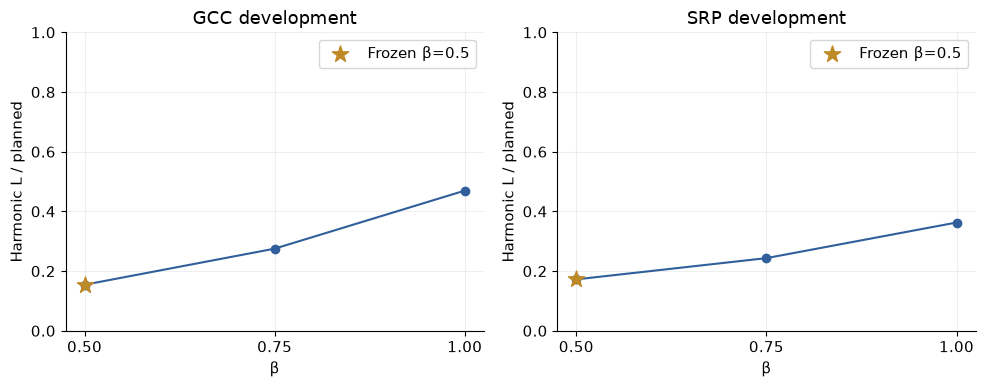

In [2]:
dev=pd.read_csv(out/'development_tradeoff.csv.gz');display(dev.round(5))
fig,axes=plt.subplots(1,2,figsize=(10,4))
for ax,method in zip(axes,METHODS):
    rows=dev[dev.method==method].sort_values('beta');ax.plot(rows.beta,rows.harmonic_loss,'o-',color=colors['baseline'])
    beta=frozen['selected_beta'][method];point=rows[rows.beta==beta].iloc[0]
    ax.scatter([beta],[point.harmonic_loss],s=150,marker='*',color=colors['selected'],label=f'Frozen β={beta:g}',zorder=3)
    ax.set(title=short[method]+' development',xlabel='β',ylabel='Harmonic L / planned',ylim=(0,1),xticks=[.5,.75,1]);ax.legend()
fig.tight_layout();fig.savefig(out/'development_selection.png',dpi=140);plt.show()

### 2. Evaluation: L и доступность направлений

Равный вес station/replicate cells внутри class/range. Denominator L включает
все planned frames, в том числе invalid. Таблицы `evaluation_metrics.csv.gz`
сохраняют каждую станцию и реализацию, all/stride, conditional median/P95,
>5/10/30° и durations серий ошибок.

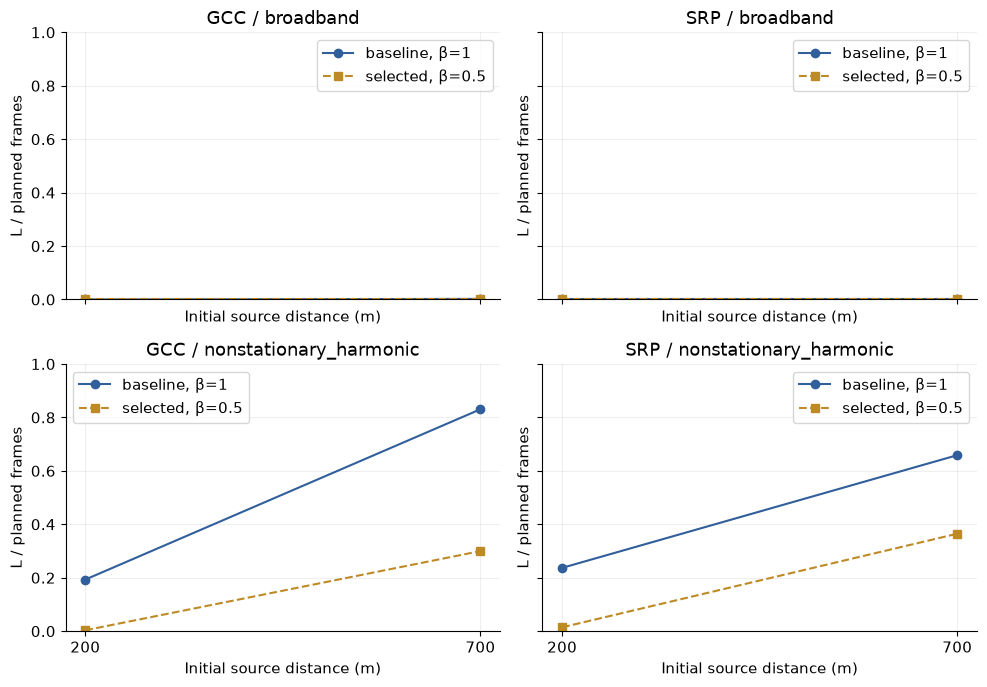

,method,beta,source_class,loss,valid_fraction,median_deg,p95_deg
24,all_6_equal_gcc_wls,1.0,broadband,0.00110,1.0,0.27949,0.60475
26,all_6_equal_gcc_wls,1.0,nonstationary_harmonic,0.51184,1.0,15.60189,72.42817
28,all_6_equal_gcc_wls,0.5,broadband,0.00000,1.0,0.24347,0.52350
30,all_6_equal_gcc_wls,0.5,nonstationary_harmonic,0.15154,1.0,4.86735,19.43540
32,equal_weight_srp_phat,1.0,broadband,0.00000,1.0,0.27726,0.59340
34,equal_weight_srp_phat,1.0,nonstationary_harmonic,0.44783,1.0,10.28888,56.43691
36,equal_weight_srp_phat,0.5,broadband,0.00000,1.0,0.24278,0.51983
38,equal_weight_srp_phat,0.5,nonstationary_harmonic,0.18958,1.0,5.82881,15.91175


In [3]:
evaluation=pd.read_csv(out/'evaluation_metrics.csv.gz')
all_frames=evaluation[evaluation.sampling=='all']
fig,axes=plt.subplots(2,2,figsize=(10,7),sharex=True,sharey=True)
for column,method in enumerate(METHODS):
    for row,cls in enumerate(['broadband','nonstationary_harmonic']):
        ax=axes[row,column]
        for mode,beta in [('baseline',1.),('selected',frozen['selected_beta'][method])]:
            g=all_frames[(all_frames.method==method)&(all_frames.source_class==cls)&(all_frames.beta==beta)].groupby('distance_m').loss.mean()
            ax.plot(g.index,g.values,marker='o' if mode=='baseline' else 's',linestyle='-' if mode=='baseline' else '--',color=colors[mode],label=f'{mode}, β={beta:g}')
        ax.set(title=short[method]+' / '+cls,xlabel='Initial source distance (m)',ylabel='L / planned frames',ylim=(0,1),xticks=[200,700]);ax.legend()
fig.tight_layout();fig.savefig(out/'evaluation_loss.png',dpi=140);plt.show()
macro=pd.read_csv(out/'macro_metrics.csv.gz');display(macro[(macro.split=='evaluation')&(macro.sampling=='all')][['method','beta','source_class','loss','valid_fraction','median_deg','p95_deg']].round(5))

### 3. Tracking: paired baseline / selected

Прежний three-station-confirmation tracker, bias/R/Qc/history/budgets неизменны.
Только evaluation200м / replicate0, оба класса. Если выбрана β=1, selected
явно reuse идентичного baseline. Отсутствие публикаций не является нулевой ошибкой.

In [4]:
pairs=pd.read_csv(out/'paired_tracking_review.csv.gz');display(pairs[['method','source_class','beta','selected_reuses_baseline','baseline_first_confirmation_time_s_relative','selected_first_confirmation_time_s_relative','baseline_availability_fraction','selected_availability_fraction','baseline_position_rmse_m_conditional','selected_position_rmse_m_conditional','baseline_total_executed_optimizations','selected_total_executed_optimizations','selected_final_failure_reason']].round(5))

,method,source_class,beta,selected_reuses_baseline,baseline_first_confirmation_time_s_relative,selected_first_confirmation_time_s_relative,baseline_availability_fraction,selected_availability_fraction,baseline_position_rmse_m_conditional,selected_position_rmse_m_conditional,baseline_total_executed_optimizations,selected_total_executed_optimizations,selected_final_failure_reason
0,all_6_equal_gcc_wls,broadband,0.5,False,1.05531,1.05531,0.94545,0.94545,2.10492,2.13921,2,2,NaN
1,all_6_equal_gcc_wls,nonstationary_harmonic,0.5,False,NaN,NaN,0.00000,0.00000,NaN,NaN,128,106,tentative_initialization_unconfirmed
2,equal_weight_srp_phat,broadband,0.5,False,1.05531,1.05531,0.94545,0.94545,2.10087,2.13425,2,2,NaN
3,equal_weight_srp_phat,nonstationary_harmonic,0.5,False,NaN,NaN,0.00000,0.00000,NaN,NaN,128,106,tentative_initialization_unconfirmed


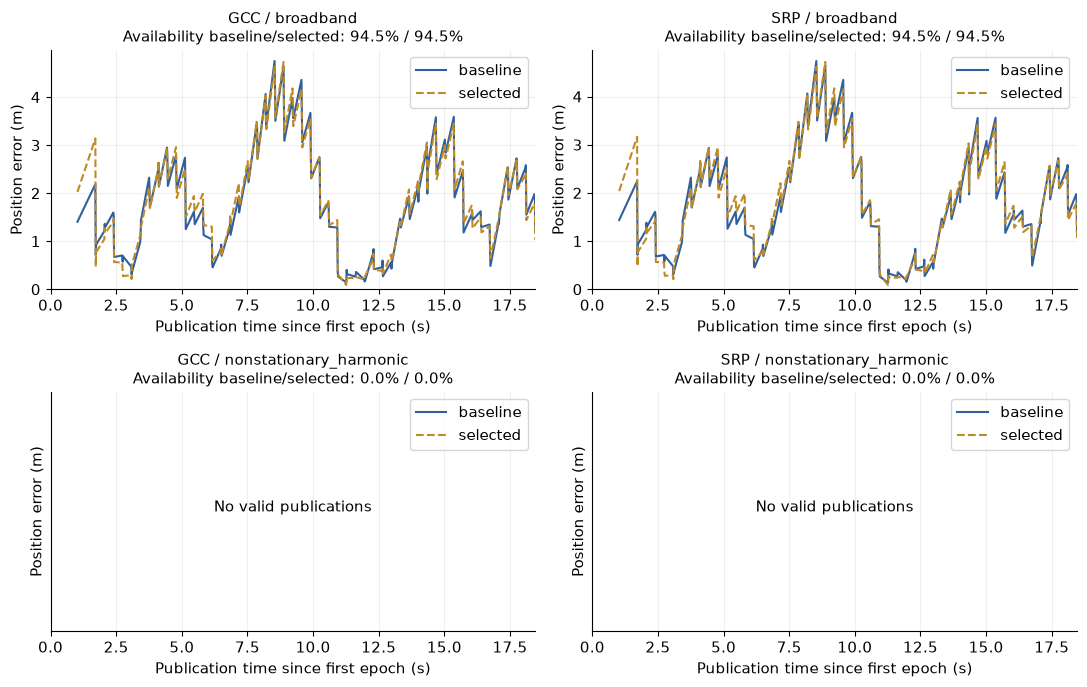

In [5]:
fig,axes=plt.subplots(2,2,figsize=(11,7))
for row,(cls,index) in enumerate([('broadband',8),('nonstationary_harmonic',12)]):
    for column,method in enumerate(METHODS):
        ax=axes[row,column];available=[]
        for mode in ['baseline','selected']:
            directory=replay_dir(out,index,method,'baseline' if mode=='selected' and frozen['selected_beta'][method]==1 else mode)
            data=pd.read_csv(directory/f'tracking_{method}_three_station_confirmation.csv.gz')
            valid=data.valid.astype(str).str.lower().eq('true');error=pd.to_numeric(data.position_error_m,errors='coerce').where(valid)
            times=data.processing_time_s-data.processing_time_s.iloc[0]
            ax.plot(times,error,color=colors[mode],linestyle='-' if mode=='baseline' else '--',label=mode)
            available.append(float(valid.mean()))
        ax.set(title=short[method]+' / '+cls,xlabel='Publication time since first epoch (s)',ylabel='Position error (m)');ax.legend(loc='upper right')
        ax.set_xlim(float(times.min()),float(times.max()))
        ax.set_title(short[method]+' / '+cls+f'\nAvailability baseline/selected: {available[0]:.1%} / {available[1]:.1%}',fontsize=11)
        ax.set_ylim(bottom=0)
        if not any(available):
            ax.set_ylim(0,1);ax.set_yticks([])
            ax.text(.5,.5,'No valid publications',ha='center',transform=ax.transAxes)
fig.tight_layout();fig.savefig(out/'tracking_errors.png',dpi=140);plt.show()

### 4. Механизм: заранее выбранный harmonic frame0 / S0 / evaluation200м r0

Сохранены реальные weights, active bins, weighted spectra, lag curves и SRP
5° карты для frames0/32/last трёх станций. Дополнительной нормировки корреляций нет.
Наличие/исчезновение конкурирующего пика само по себе не устанавливает истинный
DOA и не разделяет причинно подавление noise bins и periodic ambiguity.
SRP color ranges индивидуальны и подписаны в исходных score units; lag curves
показаны на общей baseline scale. Это настройка рисунка, не нормировка алгоритма.

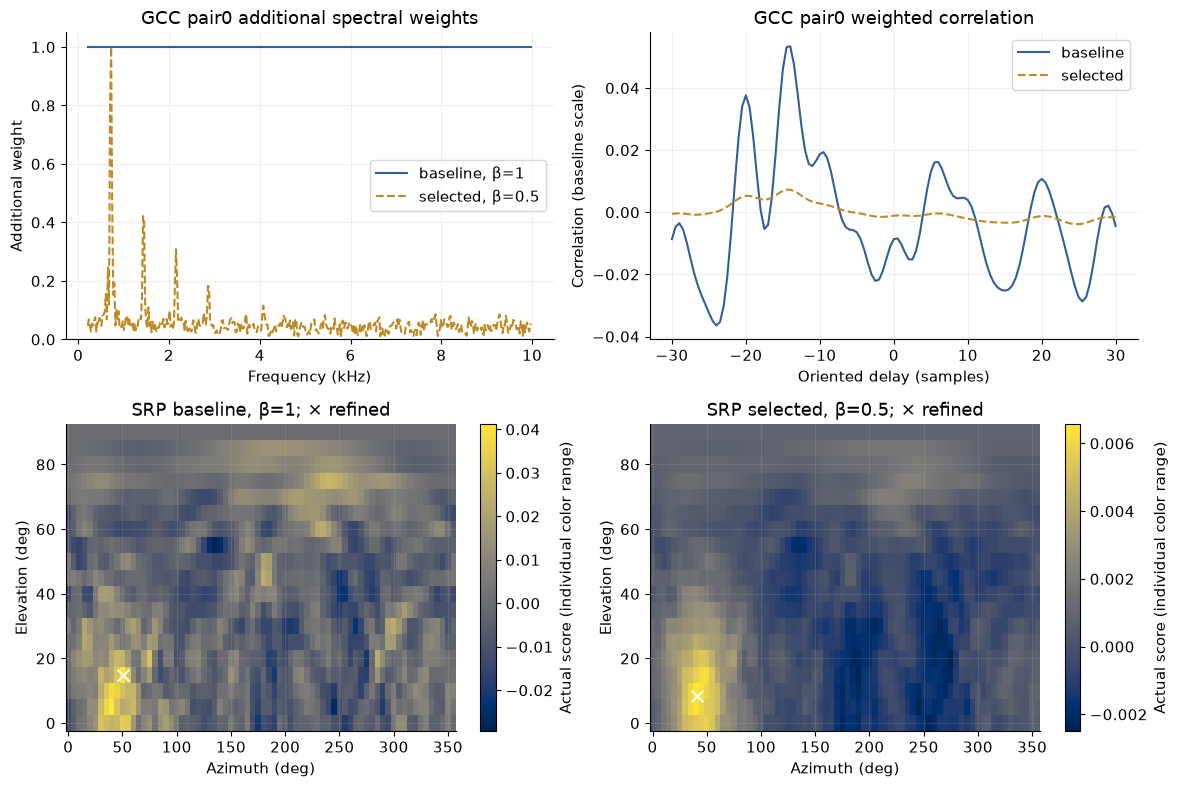

In [6]:
directory=out/'runs'/'12'
def diagnostic(beta):return np.load(directory/f'curves_S0_0_b{beta}.npz',allow_pickle=False)
base=diagnostic(1.);gcc=diagnostic(frozen['selected_beta'][METHODS[0]]);srp=diagnostic(frozen['selected_beta'][METHODS[1]])
fig,axes=plt.subplots(2,2,figsize=(12,8))
for mode,data in [('baseline',base),('selected',gcc)]:
    band=(data['frequencies_hz']>=200)&(data['frequencies_hz']<=10000)
    axes[0,0].plot(data['frequencies_hz'][band]/1000,data['weights_0'][band],color=colors[mode],linestyle='-' if mode=='baseline' else '--',label=f'{mode}, β={float(data["beta"]):g}')
    axes[0,1].plot(data['lags_0'],data['correlation_0'],color=colors[mode],linestyle='-' if mode=='baseline' else '--',label=mode)
axes[0,0].set(title='GCC pair0 additional spectral weights',xlabel='Frequency (kHz)',ylabel='Additional weight',ylim=(0,1.05));axes[0,0].legend()
axes[0,1].set(title='GCC pair0 weighted correlation',xlabel='Oriented delay (samples)',ylabel='Correlation (baseline scale)');axes[0,1].legend()
limits=[np.nanmin(base['srp_scores']),np.nanmin(srp['srp_scores']),np.nanmax(base['srp_scores']),np.nanmax(srp['srp_scores'])]
for ax,mode,data in [(axes[1,0],'baseline',base),(axes[1,1],'selected',srp)]:
    im=ax.imshow(data['srp_scores'].reshape(19,72),origin='lower',extent=[-2.5,357.5,-2.5,92.5],aspect='auto',vmin=float(np.nanmin(data['srp_scores'])),vmax=float(np.nanmax(data['srp_scores'])),cmap='cividis')
    direction=data['srp_selected_direction']
    if np.isfinite(direction).all():
        az=np.rad2deg(np.arctan2(direction[1],direction[0]))%360;el=np.rad2deg(np.arcsin(direction[2]));ax.scatter([az],[el],marker='x',color='white',s=70,label='Refined estimate')
    ax.set(title=f'SRP {mode}, β={float(data["beta"]):g}; × refined',xlabel='Azimuth (deg)',ylabel='Elevation (deg)');fig.colorbar(im,ax=ax,label='Actual score (individual color range)')
fig.tight_layout();fig.savefig(out/'mechanism_frame.png',dpi=140);plt.show()

## Takeaways

Перспективность оценивается отдельно по методу, не переносится между GCC/SRP.
Выполнение frozen frontend criterion не заменяет uncertainty calibration.
Устойчивость harmonic tracking оценивается вместе с availability, conditional
coordinate errors, >50м/all epochs и реальными причинами отказов.
Общие source banks и две реализации не дают population qualification;
frames/publication epochs нельзя считать независимыми trials.

In [7]:
for r in review['evaluation_criteria']:
    reduction=r['harmonic_loss_relative_reduction']
    display(Markdown(f"**{short[r['method']]}**, β={r['beta']:g}: harmonic L {r['baseline_harmonic_loss']:.3%} → {r['selected_harmonic_loss']:.3%}; relative reduction {reduction:.3%}; promising for further calibration: **{r['promising_for_further_calibration']}**."))
for _,p in pairs[pairs.source_class=='nonstationary_harmonic'].iterrows():
    display(Markdown(f"**{short[p.method]} harmonic selected:** availability {p.selected_availability_fraction:.3%}; RMSE {"undefined" if pd.isna(p.selected_position_rmse_m_conditional) else p.selected_position_rmse_m_conditional}; final failure: {p.selected_final_failure_reason}."))
print('Gate disabled:',not review['ambiguity_gate_enabled'])

**GCC**, β=0.5: harmonic L 51.184% → 15.154%; relative reduction 70.394%; promising for further calibration: **True**.

**SRP**, β=0.5: harmonic L 44.783% → 18.958%; relative reduction 57.668%; promising for further calibration: **True**.

**GCC harmonic selected:** availability 0.000%; RMSE undefined; final failure: tentative_initialization_unconfirmed.

**SRP harmonic selected:** availability 0.000%; RMSE undefined; final failure: tentative_initialization_unconfirmed.

Gate disabled: True
